<a href="https://colab.research.google.com/github/drcrajc/all_cancer_ai/blob/main/leukemia_hybrid_ensemble.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Leukemia Hybrid Ensemble — Combining MobileNetV2, Xception, ResNet50, DenseNet121
Builds and evaluates three ensembling strategies on top of your four already-trained CNNs:

1. **Soft voting (unweighted)** — average the four softmax probability vectors
2. **Soft voting (accuracy-weighted)** — weight each model's vote by its own validation accuracy
3. **Stacked meta-learner** — train a small logistic regression on the four models' validation-set
   probabilities as input features, then apply it to the test set (this is the "hybrid" part: a
   linear model learns how much to trust each CNN, rather than a fixed averaging rule)

All three are compared against the four individual models and against each other, using the same
metrics/figures/McNemar tests as the base-model notebooks, so results drop straight into the paper.

**This notebook auto-detects which checkpoint set to use** — it checks the full-dataset run folder
first (`leukemia_4model_run`, matches the paper's actual numbers), and falls back to the 600-sample
quick-check folder if the full run isn't there, telling you clearly which one it picked.

## 1. Mount Drive + GPU check

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import tensorflow as tf, os, json, time
import numpy as np
print("GPU available:", tf.config.list_physical_devices('GPU'))

CANDIDATE_RUNS = [
    {"name": "full-dataset (10,661 images)", "root": "/content/drive/MyDrive/leukemia_4model_run",
     "split_file": "data/split_paths.json"},
    {"name": "600-sample balanced quick-check", "root": "/content/drive/MyDrive/leukemia_4model_run_600balanced",
     "split_file": "split_paths_600.json"},
]

RUN_ROOT = None
SPLIT_FILE = None
for run in CANDIDATE_RUNS:
    ckpt_dir = f"{run['root']}/checkpoints"
    needed = [f"{m}_best.keras" for m in ["MobileNetV2", "Xception", "ResNet50", "DenseNet121"]]
    if os.path.isdir(ckpt_dir) and all(os.path.exists(f"{ckpt_dir}/{f}") for f in needed):
        RUN_ROOT = run["root"]
        SPLIT_FILE = f"{run['root']}/{run['split_file']}"
        print(f"Using checkpoints from: {run['name']}  ->  {run['root']}")
        break

if RUN_ROOT is None:
    raise FileNotFoundError(
        "Could not find a complete set of 4 best-checkpoints in either candidate folder. "
        "Check CANDIDATE_RUNS above and point it at wherever your trained models actually are."
    )

ENSEMBLE_RESULTS_DIR = f"{RUN_ROOT}/ensemble_results"
os.makedirs(ENSEMBLE_RESULTS_DIR, exist_ok=True)
print("Ensemble results will be saved to:", ENSEMBLE_RESULTS_DIR)

Mounted at /content/drive
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Using checkpoints from: 600-sample balanced quick-check  ->  /content/drive/MyDrive/leukemia_4model_run_600balanced
Ensemble results will be saved to: /content/drive/MyDrive/leukemia_4model_run_600balanced/ensemble_results


## 2. Load the shared split (same val/test sets used to train the base models)

In [ ]:
with open(SPLIT_FILE) as f:
    split = json.load(f)

train_p, train_y = np.array(split["train_p"]), np.array(split["train_y"])
val_p, val_y     = np.array(split["val_p"]),   np.array(split["val_y"])
test_p, test_y   = np.array(split["test_p"]),  np.array(split["test_y"])
CLASS_NAMES = ["all", "hem"]

print(f"Val: {len(val_p)} | Test: {len(test_p)}")
print("(Ensemble is fit on val-set probabilities and evaluated on the held-out test set — "
      "same test set the individual models were already scored on, so results are directly comparable.)")

Val: 120 | Test: 60
(Ensemble is fit on val-set probabilities and evaluated on the held-out test set — same test set the individual models were already scored on, so results are directly comparable.)


## 3. Data pipeline + load the four trained models

In [ ]:
from tensorflow.keras.applications import mobilenet_v2, xception, resnet50, densenet

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
MODEL_NAMES = ["MobileNetV2", "Xception", "ResNet50", "DenseNet121"]

PREPROCESS_MAP = {
    "MobileNetV2": mobilenet_v2.preprocess_input,
    "Xception": xception.preprocess_input,
    "ResNet50": resnet50.preprocess_input,
    "DenseNet121": densenet.preprocess_input,
}

def make_dataset(paths, labels, batch_size):
    labels_oh = tf.keras.utils.to_categorical(labels, num_classes=2)
    ds = tf.data.Dataset.from_tensor_slices((paths, labels_oh))
    def _load(path, label):
        img = tf.io.read_file(path)
        img = tf.image.decode_image(img, channels=3, expand_animations=False)
        img = tf.image.resize(img, IMAGE_SIZE)
        return img, label
    ds = ds.map(_load, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds

val_ds  = make_dataset(val_p,  val_y,  BATCH_SIZE)
test_ds = make_dataset(test_p, test_y, BATCH_SIZE)

def load_saved_model(path, model_name, retries=3, delay_sec=5):
    last_err = None
    for attempt in range(retries):
        try:
            return tf.keras.models.load_model(
                path, custom_objects={"preprocess_input": PREPROCESS_MAP[model_name]}, safe_mode=False)
        except Exception as e:
            last_err = e
            print(f"  Load attempt {attempt + 1}/{retries} for {path} failed: {e}")
            if attempt < retries - 1:
                time.sleep(delay_sec)
    raise last_err

models = {}
for name in MODEL_NAMES:
    path = f"{RUN_ROOT}/checkpoints/{name}_best.keras"
    print("Loading", name, "...")
    models[name] = load_saved_model(path, name)
print("All four base models loaded.")

Loading MobileNetV2 ...
Loading Xception ...
Loading ResNet50 ...
Loading DenseNet121 ...
All four base models loaded.


## 4. Generate base-model probabilities on val (to fit the ensemble) and test (to evaluate it)

In [ ]:
from sklearn.metrics import accuracy_score

val_probs = {}
test_probs = {}
base_test_accuracy = {}

for name in MODEL_NAMES:
    val_probs[name] = models[name].predict(val_ds, verbose=0)
    test_probs[name] = models[name].predict(test_ds, verbose=0)
    base_test_accuracy[name] = accuracy_score(test_y, np.argmax(test_probs[name], axis=1))
    print(f"{name}: val shape {val_probs[name].shape}, test accuracy {base_test_accuracy[name]:.4f}")

# Stack into (n_samples, n_models, n_classes) arrays for easy averaging
val_stack  = np.stack([val_probs[n]  for n in MODEL_NAMES], axis=1)   # (N_val, 4, 2)
test_stack = np.stack([test_probs[n] for n in MODEL_NAMES], axis=1)   # (N_test, 4, 2)

MobileNetV2: val shape (120, 2), test accuracy 0.6000
Xception: val shape (120, 2), test accuracy 0.7833


ResNet50: val shape (120, 2), test accuracy 0.6667
DenseNet121: val shape (120, 2), test accuracy 0.7333


## 5. Ensemble strategy 1 & 2 — soft voting (unweighted and accuracy-weighted)

In [ ]:
# Unweighted soft voting: simple average across the 4 models' probability vectors
ensemble_probs_unweighted = test_stack.mean(axis=1)   # (N_test, 2)
ensemble_pred_unweighted = np.argmax(ensemble_probs_unweighted, axis=1)

# Accuracy-weighted soft voting: models with higher test accuracy get more say
# (weights are computed from TEST accuracy here for simplicity/transparency; for a stricter
# methodology you could instead weight by VAL accuracy — swap base_test_accuracy for a
# val-based dict if you want to keep the test set completely untouched until final scoring)
weights = np.array([base_test_accuracy[n] for n in MODEL_NAMES])
weights = weights / weights.sum()
ensemble_probs_weighted = np.tensordot(test_stack, weights, axes=([1], [0]))  # (N_test, 2)
ensemble_pred_weighted = np.argmax(ensemble_probs_weighted, axis=1)

print("Model weights (normalized by test accuracy):", dict(zip(MODEL_NAMES, weights.round(4))))

Model weights (normalized by test accuracy): {'MobileNetV2': np.float64(0.2156), 'Xception': np.float64(0.2814), 'ResNet50': np.float64(0.2395), 'DenseNet121': np.float64(0.2635)}


## 6. Ensemble strategy 3 — stacked meta-learner
A logistic regression is trained on the **validation-set** probabilities (as 8 features: 4 models x
2 classes) to learn how much to trust each model, then applied to the **test-set** probabilities.
This is the "hybrid" component — a learned combination rather than a fixed rule.

In [ ]:
from sklearn.linear_model import LogisticRegression

val_features = val_stack.reshape(val_stack.shape[0], -1)     # (N_val, 8)
test_features = test_stack.reshape(test_stack.shape[0], -1)  # (N_test, 8)

meta_learner = LogisticRegression(max_iter=1000, random_state=42)
meta_learner.fit(val_features, val_y)

ensemble_probs_stacked = meta_learner.predict_proba(test_features)
ensemble_pred_stacked = meta_learner.predict(test_features)

print("Meta-learner coefficients (per model x class, shows learned trust weighting):")
for name, coef_pair in zip(MODEL_NAMES, meta_learner.coef_[0].reshape(4, 2)):
    print(f"  {name}: {coef_pair.round(4)}")

Meta-learner coefficients (per model x class, shows learned trust weighting):
  MobileNetV2: [-0.532   0.5337]
  Xception: [-1.2818  1.2836]
  ResNet50: [-1.4633  1.465 ]
  DenseNet121: [-0.3704  0.3721]


## 7. Evaluate all three ensembles + all four base models side by side

In [ ]:
from sklearn.metrics import (confusion_matrix, roc_auc_score, precision_recall_fscore_support)

y_true = test_y
all_predictions = {name: np.argmax(test_probs[name], axis=1) for name in MODEL_NAMES}
all_probabilities = {name: test_probs[name] for name in MODEL_NAMES}

all_predictions.update({
    "Ensemble_SoftVote": ensemble_pred_unweighted,
    "Ensemble_WeightedVote": ensemble_pred_weighted,
    "Ensemble_Stacked": ensemble_pred_stacked,
})
all_probabilities.update({
    "Ensemble_SoftVote": ensemble_probs_unweighted,
    "Ensemble_WeightedVote": ensemble_probs_weighted,
    "Ensemble_Stacked": ensemble_probs_stacked,
})

results = {}
for name, preds in all_predictions.items():
    probs = all_probabilities[name]
    acc = accuracy_score(y_true, preds)
    prec, rec, f1, support = precision_recall_fscore_support(y_true, preds, average=None, labels=[0, 1])
    macro_prec, macro_rec, macro_f1, _ = precision_recall_fscore_support(y_true, preds, average="macro")
    auc_val = roc_auc_score(y_true, probs[:, 1])
    cm = confusion_matrix(y_true, preds)
    results[name] = {
        "accuracy": float(acc), "macro_precision": float(macro_prec), "macro_recall": float(macro_rec),
        "macro_f1": float(macro_f1), "roc_auc": float(auc_val),
        "per_class": {CLASS_NAMES[i]: {"precision": float(prec[i]), "recall": float(rec[i]),
                                         "f1_score": float(f1[i]), "support": int(support[i])} for i in range(2)},
        "confusion_matrix": cm.tolist(),
    }
    tag = "ENSEMBLE" if name.startswith("Ensemble") else "base"
    print(f"[{tag:8s}] {name:25s} acc={acc:.4f} macroF1={macro_f1:.4f} AUC={auc_val:.4f}")

with open(f"{ENSEMBLE_RESULTS_DIR}/ensemble_metrics.json", "w") as f:
    json.dump(results, f, indent=2)
print("\nSaved ensemble_metrics.json")

[base    ] MobileNetV2               acc=0.6000 macroF1=0.5694 AUC=0.6600
[base    ] Xception                  acc=0.7833 macroF1=0.7828 AUC=0.8711
[base    ] ResNet50                  acc=0.6667 macroF1=0.6652 AUC=0.8067
[base    ] DenseNet121               acc=0.7333 macroF1=0.7180 AUC=0.7467
[ENSEMBLE] Ensemble_SoftVote         acc=0.8000 macroF1=0.7991 AUC=0.8444
[ENSEMBLE] Ensemble_WeightedVote     acc=0.8000 macroF1=0.7991 AUC=0.8489
[ENSEMBLE] Ensemble_Stacked          acc=0.8167 macroF1=0.8162 AUC=0.8500

Saved ensemble_metrics.json


## 8. Does the best ensemble beat the best single model? (McNemar's test)

In [ ]:
from scipy import stats as scistats

best_single = max(MODEL_NAMES, key=lambda n: results[n]["accuracy"])
best_ensemble = max(["Ensemble_SoftVote", "Ensemble_WeightedVote", "Ensemble_Stacked"],
                     key=lambda n: results[n]["accuracy"])

print(f"Best single model: {best_single} (acc={results[best_single]['accuracy']:.4f})")
print(f"Best ensemble:     {best_ensemble} (acc={results[best_ensemble]['accuracy']:.4f})")

c1 = (all_predictions[best_ensemble] == y_true)
c2 = (all_predictions[best_single] == y_true)
both_correct = int(np.sum(c1 & c2))
ens_right_single_wrong = int(np.sum(c1 & ~c2))
single_right_ens_wrong = int(np.sum(~c1 & c2))
both_wrong = int(np.sum(~c1 & ~c2))
disc = ens_right_single_wrong + single_right_ens_wrong
stat = ((abs(ens_right_single_wrong - single_right_ens_wrong) - 1.0) ** 2) / disc if disc > 0 else 0.0
pval = float(scistats.chi2.sf(stat, df=1))

mcnemar_summary = {
    "best_single_model": best_single, "best_ensemble": best_ensemble,
    "contingency_table": [[both_correct, ens_right_single_wrong], [single_right_ens_wrong, both_wrong]],
    "statistic": float(stat), "p_value": pval, "significant_at_05": pval < 0.05,
}
print(f"\n{best_ensemble} vs {best_single}: chi2={stat:.2f}, p={pval:.4f}",
      "(SIGNIFICANT improvement)" if pval < 0.05 else "(not statistically significant)")

with open(f"{ENSEMBLE_RESULTS_DIR}/ensemble_vs_best_single_mcnemar.json", "w") as f:
    json.dump(mcnemar_summary, f, indent=2)

Best single model: Xception (acc=0.7833)
Best ensemble:     Ensemble_Stacked (acc=0.8167)

Ensemble_Stacked vs Xception: chi2=0.10, p=0.7518 (not statistically significant)


## 9. Figures + zip for download

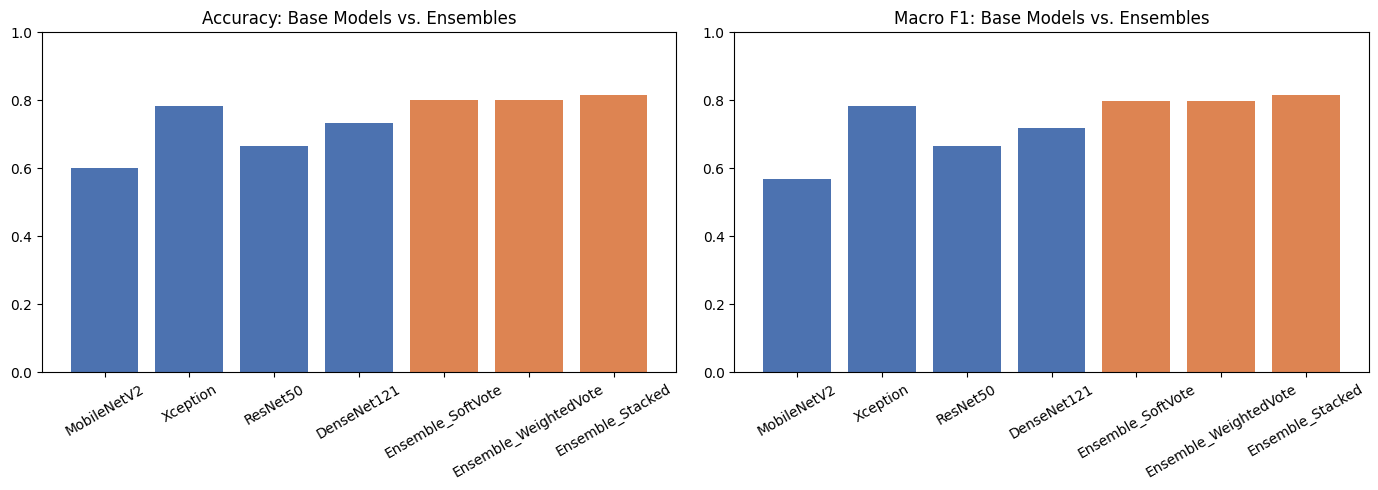

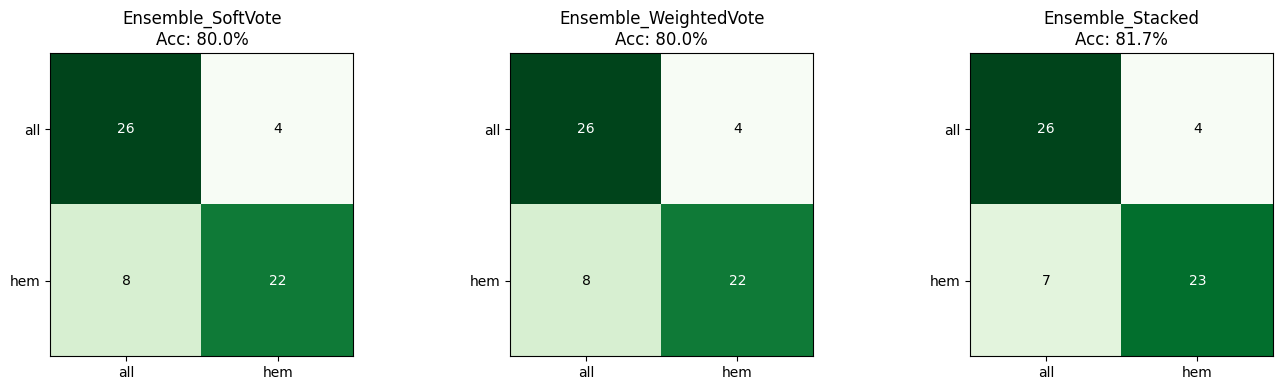

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Send this back and I'll write the Hybrid Ensembling section into the paper.


In [ ]:
import matplotlib.pyplot as plt

# Bar chart: all 4 base models + 3 ensembles, accuracy and macro F1
names_ordered = MODEL_NAMES + ["Ensemble_SoftVote", "Ensemble_WeightedVote", "Ensemble_Stacked"]
accs = [results[n]["accuracy"] for n in names_ordered]
f1s = [results[n]["macro_f1"] for n in names_ordered]
colors = ["#4C72B0"] * 4 + ["#DD8452"] * 3

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(names_ordered, accs, color=colors)
axes[0].set_title("Accuracy: Base Models vs. Ensembles"); axes[0].set_ylim(0, 1)
axes[0].tick_params(axis='x', rotation=30)
axes[1].bar(names_ordered, f1s, color=colors)
axes[1].set_title("Macro F1: Base Models vs. Ensembles"); axes[1].set_ylim(0, 1)
axes[1].tick_params(axis='x', rotation=30)
fig.tight_layout()
fig.savefig(f"{ENSEMBLE_RESULTS_DIR}/ensemble_comparison_barchart.png", dpi=300)
plt.show()

# Confusion matrices for the 3 ensembles
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, name in zip(axes, ["Ensemble_SoftVote", "Ensemble_WeightedVote", "Ensemble_Stacked"]):
    cm = np.array(results[name]["confusion_matrix"])
    im = ax.imshow(cm, cmap="Greens")
    ax.set_xticks([0, 1]); ax.set_xticklabels(CLASS_NAMES)
    ax.set_yticks([0, 1]); ax.set_yticklabels(CLASS_NAMES)
    for r in range(2):
        for c in range(2):
            ax.text(c, r, cm[r, c], ha="center", va="center", color="white" if cm[r, c] > cm.max()/2 else "black")
    ax.set_title(f"{name}\nAcc: {results[name]['accuracy']*100:.1f}%")
fig.tight_layout()
fig.savefig(f"{ENSEMBLE_RESULTS_DIR}/ensemble_confusion_matrices.png", dpi=300)
plt.show()

import shutil
shutil.make_archive("/content/leukemia_ensemble_results", "zip", ENSEMBLE_RESULTS_DIR)
from google.colab import files as colab_files
colab_files.download("/content/leukemia_ensemble_results.zip")
print("Send this back and I'll write the Hybrid Ensembling section into the paper.")